# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

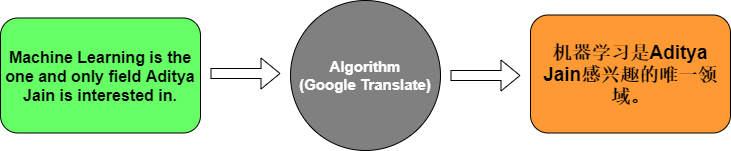

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step - accuracy: 0.0000e+00 - loss: 2.4842 - val_accuracy: 0.0000e+00 - val_loss: 2.4875
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.5714 - loss: 2.4764 - val_accuracy: 0.0000e+00 - val_loss: 2.4900
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.5714 - loss: 2.4685 - val_accuracy: 0.0000e+00 - val_loss: 2.4927
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.5714 - loss: 2.4597 - val_accuracy: 0.0000e+00 - val_loss: 2.4956
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5714 - loss: 2.4498 - val_accuracy: 0.0000e+00 - val_loss: 2.4989
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.5714 - loss: 2.4384 - val_accuracy: 0.0000e+00 - val_loss: 2.5026
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.5714 - loss: 2.4251 - val_accuracy: 0.0000e+00 - val_loss: 2.5067
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4096 - v

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

**1. What does the Embedding layer do to a word index?**
It changes the word number into a vector, so the model can understand the word's meaning instead of just seeing an ID.

**2. What is the role of the Encoder LSTM?**
It reads the English sentence and turns it into one vector that summarizes the whole sentence.

**3. What does the Decoder LSTM do?**
It takes that summary and produces the output one step at a time, one step for each French word.

**4. Why do we use softmax in the final layer?**
To get a probability for every French word, so we can pick the word with the highest probability.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [11]:
import kagglehub
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [12]:
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
print(os.listdir(path))

csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file))
df.columns = ["english", "french"]
print(df.shape)
df.head()

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
['eng_-french.csv']
(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [13]:
df = df.dropna().drop_duplicates(subset="english")
df["eng_len"] = df["english"].str.split().str.len()
df["frn_len"] = df["french"].str.split().str.len()
df = df[(df["eng_len"] <= 6) & (df["frn_len"] <= 8)]
df = df.sample(min(40000, len(df)), random_state=42).reset_index(drop=True)

english_sentences = df["english"].tolist()
french_sentences = df["french"].tolist()
print(len(english_sentences))
print(english_sentences[:3])
print(french_sentences[:3])

40000
['Two families live in that house.', 'An olive branch symbolises peace.', 'Come on, admit it.']
['Deux familles vivent dans cette maison.', "Une branche d'olivier symbolise la paix.", 'Allez, admets-le.']


In [14]:
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_word_index = tokenizer_eng.word_index
print(f"eng_sequences = {eng_sequences[:3]}")
print(f"eng vocab size = {len(eng_word_index)}")

eng_sequences = [[241, 2265, 219, 23, 10, 162], [64, 4953, 3734, 4954, 1098], [83, 35, 1220, 11]]
eng vocab size = 8278


In [15]:
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_word_index = tokenizer_frn.word_index
print(f"frn_sequences = {frn_sequences[:3]}")
print(f"frn vocab size = {len(frn_word_index)}")

frn_sequences = [[124, 2708, 1121, 45, 43, 115], [21, 4985, 7110, 7111, 9, 1176], [515, 7112, 7]]
frn vocab size = 14226


In [16]:
eng_padded = pad_sequences(eng_sequences, padding="post")
frn_padded = pad_sequences(frn_sequences, padding="post")
print(f"eng_padded shape = {eng_padded.shape}")
print(f"frn_padded shape = {frn_padded.shape}")

eng_padded shape = (40000, 9)
frn_padded shape = (40000, 11)


In [17]:
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=256, mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(256)),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(512, return_sequences=True),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax'))
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

history = model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=60, batch_size=128, validation_split=0.2, callbacks=[early])

loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 24s 95ms/step - accuracy: 0.5374 - loss: 3.8995 - val_accuracy: 0.5510 - val_loss: 3.3128
Epoch 2/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 19s 93ms/step - accuracy: 0.5548 - loss: 3.2407 - val_accuracy: 0.5589 - val_loss: 3.2154
Epoch 3/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 91ms/step - accuracy: 0.5589 - loss: 3.1528 - val_accuracy: 0.5620 - val_loss: 3.1789
Epoch 4/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 91ms/step - accuracy: 0.5637 - loss: 3.0778 - val_accuracy: 0.5725 - val_loss: 3.1032
Epoch 5/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 91ms/step - accuracy: 0.5739 - loss: 2.9723 - val_accuracy: 0.5795 - val_loss: 3.0310
Epoch 6/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 19s 93ms/step - accuracy: 0.5851 - loss: 2.8605 - val_accuracy: 0.5925 - val_loss: 2.9300
Epoch 7/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 92ms/step - accuracy: 0.5988 - loss: 2.7253 - val_accuracy: 0.6034 - val_loss: 2.8334
Epoch 8/60
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 91ms/step - accuracy: 0.6106 - loss: 2.5991 - 

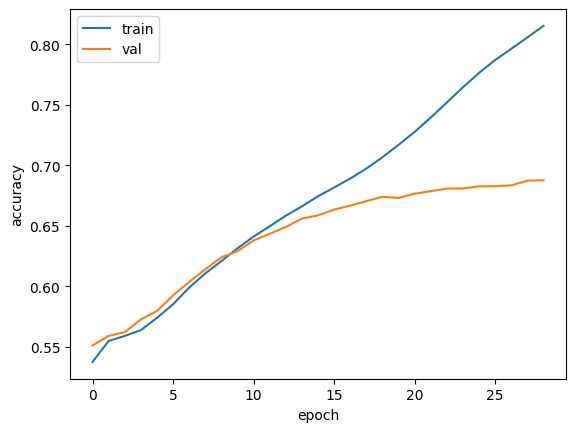

In [18]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()

In [19]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1], padding="post")
    predicted_sequence = model.predict(padded_sequence, verbose=0)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

for i in range(5):
    eng = tokenizer_eng.sequences_to_texts([eng_test[i].tolist()])[0]
    real = tokenizer_frn.sequences_to_texts([frn_test[i].tolist()])[0]
    pred = translate_sentence(eng, model, tokenizer_eng, tokenizer_frn)
    print(f'Input: {eng}\nActual: {real}\nPredicted: {pred}\n')

Input: she does know it
Actual: elle sait certainement cela
Predicted: elle sait sait

Input: you read too much
Actual: vous lisez trop
Predicted: tu as trop fatigué

Input: where have you been this week
Actual: où étiez vous cette semaine
Predicted: où as tu couché cette semaine

Input: the rice is still warm
Actual: le riz est encore chaud
Predicted: la guerre est toujours le finie

Input: i am loved by my parents
Actual: mes parents m'adorent
Predicted: je suis mes mes



In [20]:
product_sentences = ["This is a good price.", "I love this shirt.", "The shoes are too big.", "Where is my order?"]

for s in product_sentences:
    print(f'Input: {s}\nTranslation: {translate_sentence(s, model, tokenizer_eng, tokenizer_frn)}\n')

Input: This is a good price.
Translation: c'est un beau garçon

Input: I love this shirt.
Translation: j'aime cette chanson

Input: The shoes are too big.
Translation: les enfants sont très

Input: Where is my order?
Translation: où est mon téléphone

